# 01 · Veri Keşfi (EDA)

**Amaç:** Model kurmadan önce veriyi tanımak ve ön işlemede vereceğimiz kararları **veriye dayandırmak.**

| Bölüm | Soru |
|---|---|
| **A. Veri setinin yapısı** | Elimizde ne var? Hangisi veri, hangisi metadata? |
| **B. Katalog analizi** | Sınıflar dengeli mi? Hangi yılları alalım? Sızıntı var mı? |
| **C. Radar görüntülerini tanıma** | Hortum radarda neye benziyor? Grafikler nasıl okunur? |
| **D. Ham veri analizi** | Hangi değişkeni, hangi tarama açısını, hangi zaman adımını kullanalım? Değer aralıkları ve ölçüm hassasiyeti ne? |

Colab'da CPU yeterli. C ve D bölümleri için 2017 arşivinden yaklaşık 1.500 örnek okunur (5–10 dakika).

In [4]:
# --- Kurulum: hem Google Colab'da hem kendi bilgisayarında çalışır ---
import os, sys
from pathlib import Path

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive, userdata
    drive.mount("/content/drive")                     # işlenmiş veri Drive'da saklanır
    REPO = Path("/content/tornado-cnn")
    if not REPO.exists():
        try:                                          # repo private ise: Colab Secrets'taki token
            token = userdata.get("GITHUB_TOKEN") + "@"
        except Exception:                             # repo public ise token gerekmez
            token = ""
        !git clone -q https://{token}github.com/baevv/tornado-cnn.git {REPO}
    else:
        !git -C {REPO} pull -q
    %pip install -q h5netcdf h5py
    os.chdir(REPO)
else:
    REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

sys.path.insert(0, str(REPO))
# src/ klasöründen daha önce yüklenmiş kodu bellekten sil: git pull ile gelen yeni kod
# bir sonraki import'ta kullanılsın (oturumu yeniden başlatmaya gerek kalmasın).
for _m in [m for m in sys.modules if m == "src" or m.startswith("src.")]:
    del sys.modules[_m]

print("Colab" if IN_COLAB else "Yerel", "| repo:", REPO)

Mounted at /content/drive
Colab | repo: /content/tornado-cnn


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.helper import paths, tornet, viz, eda

cfg = paths.load_config()
DATA = paths.data_dir()
print("veri klasörü:", DATA)
print("ayarlar:", cfg)

veri klasörü: /content/drive/MyDrive/tornado-cnn/data
ayarlar: {'years': [2015, 2017, 2019], 'variables': ['DBZ', 'VEL', 'WIDTH'], 'sweep': 0, 'frame': -1, 'drive_subdir': 'tornado-cnn'}


## A. Veri setinin yapısı

### A1. Veri iki parçadan oluşuyor

```
catalog.csv  ──── filename sütunu ────>  .nc dosyası
(metadata: her örnek hakkında bilgi)      (ham radar verisi + dosya içi metadata)
203.133 satır, 38 MB                       her örnek bir dosya, toplam ~170 GB
```

* **Katalog** her örneğin ne zaman, nerede, hangi fırtınadan alındığını ve etiketini söyler. Radar verisi içermez.
* **`.nc` dosyası** radar ölçümlerinin kendisidir. Modelin göreceği veri buradan gelir.

### A2. Katalog sütunları: hangisi ne işe yarıyor?

Katalog modelin girdisi **değildir**. Örnekleri düzenlemek, etiketlemek ve bölmek için kullanılır.

| Sütun | Anlamı | Kullanım | Neden? |
|---|---|---|---|
| `category` | `TOR` / `WRN` / `NUL` | ✅ **Etiket** | TOR = 1, diğerleri = 0 |
| `type` | `train` / `test` | ✅ **Bölme** | Veri setinin hazır test kümesi |
| `episode_id` | Fırtına olayı | ✅ **Bölme** | Aynı fırtınanın örnekleri eğitim ve doğrulamaya bölünmesin (sızıntı) |
| `ef_number` | Hortum şiddeti (EF0–EF4; hortum yoksa −1) | ✅ Sadece analiz | Eğitime girmez; sonra "güçlü hortumlar daha mı kolay bulunuyor?" diye bakılır |
| `filename` | `.nc` dosyasının adı | ✅ Eşleştirme | Katalog satırını radar dosyasına bağlar |
| `start_time`, `end_time` | Örneğin kapsadığı zaman aralığı | ✅ Yıl seçimi | Yıl buradan çıkarılır |
| `event_id` | Tek bir hortum / uyarı kaydı | ❌ | Bölme için `episode_id` daha kapsayıcı |
| `lat`, `lon`, `site_name` | Fırtınanın konumu, radar istasyonu | ❌ | Model konumdan kısayol öğrenmesin ("Oklahoma'daysa hortum") |
| `az_min`, `az_max`, `rng_min`, `rng_max` | Görüntünün radara göre açı ve mesafe sınırları | ❌ | Bu bilgi zaten `.nc` dosyasında var |

Biz iki sütun ekliyoruz: `year` (yıl) ve `label` (TOR = 1, WRN/NUL = 0).

| `category` | anlamı | `label` |
|---|---|---|
| `TOR` | doğrulanmış hortum | **1** |
| `WRN` | hortum uyarısı verilmiş ama hortum çıkmamış (**zor negatif**) | 0 |
| `NUL` | rastgele seçilmiş fırtına, hortum yok | 0 |

In [6]:
cat = tornet.get_catalog(DATA)
print(f"{len(cat):,} örnek")
used_cols = ["filename", "type", "category", "label", "ef_number", "episode_id", "year"]
cat[used_cols].head()

203,133 örnek


,filename,type,category,label,ef_number,episode_id,year
0,train/2013/NUL_130831_234007_KBGM_467173s_B5.nc,train,NUL,0,-1.0,77417,2013
1,train/2013/NUL_130831_234422_KBGM_467173s_K7.nc,train,NUL,0,-1.0,77417,2013
2,train/2013/NUL_130831_234837_KBGM_467173s_X3.nc,train,NUL,0,-1.0,77417,2013
3,train/2013/NUL_130901_000121_KBGM_467173s_B5.nc,train,NUL,0,-1.0,77417,2013
4,train/2013/NUL_130901_001405_KBGM_467173s_D7.nc,train,NUL,0,-1.0,77417,2013


### A3. Bir `.nc` dosyasının içi: hangisi veri, hangisi metadata?

| İçerik | Tür | Kullanım |
|---|---|---|
| `DBZ`, `VEL`, `KDP`, `RHOHV`, `ZDR`, `WIDTH` | **Ham radar verisi** (6 değişken) | Hangilerini kullanacağımıza **D bölümünde** karar veriyoruz |
| `frame_labels` | Her zaman adımının etiketi | ✅ Etiketin kaynağı (son kare) |
| `time`, `azimuth`, `range`, `elevation` | Koordinatlar (metadata) | Sadece grafik çizmek için |
| `nyquist_velocity` | Radarın ölçebildiği en yüksek hız | ❌ Ölçüm ayarı, fırtına hakkında bilgi değil |
| `range_folded_mask` | Ölçümün belirsiz olduğu pikseller | ❌ Bu pikseller zaten boş (NaN) olarak geliyor |

**6 radar değişkeninin anlamı:**

| Değişken | Ölçtüğü şey | Hortum ile ilişkisi |
|---|---|---|
| **DBZ** (yansıtıcılık) | Havada ne kadar yağmur/dolu var | Fırtınanın şekli; hortumlu fırtınalarda bazen **kanca** şekli |
| **VEL** (radyal hız) | Rüzgarın radara doğru (−) ya da radardan uzağa (+) hızı | Hortum = yan yana yaklaşan ve uzaklaşan rüzgar (**hız çifti**) |
| **WIDTH** (hız dağınıklığı) | Bir pikseldeki hızların ne kadar dağınık olduğu | Türbülans ve dönme bu değeri artırır |
| **KDP** | Yağışın yoğunluğu (çift kutuplu ölçüm) | Yoğun yağış, dolu |
| **RHOHV** | Pikseldeki parçacıkların ne kadar benzer olduğu | Hortumun kaldırdığı **enkaz** düşük değer verir |
| **ZDR** | Parçacıkların yatay/dikey şekli | Enkaz değeri 0'a yaklaştırır |

Her değişkenin boyutu `(time=4, azimuth=120, range=240, sweep=2)`: 5 dakika arayla **4 zaman adımı**, 0,5°'lik **120 açı** hücresi (60°), 250 m'lik **240 mesafe** hücresi (60 km) ve 0,5° ile 0,9°'lik **2 tarama açısı**.

In [7]:
first = tornet.sample_from_tar(tornet.tar_url(2017), per_category={"TOR": 1})
ds0 = next(iter(first.values()))
pd.DataFrame(
    [{"değişken": k, "boyutlar": str(v.dims), "şekil": str(v.shape), "tür": str(v.dtype)} for k, v in ds0.data_vars.items()]
).set_index("değişken")

,boyutlar,şekil,tür
değişken,,,
elevation,"('sweep',)","(2,)",float64
frame_labels,"('time',)","(4,)",uint8
nyquist_velocity,"('time', 'sweep')","(4, 2)",float32
azimuth_limits,"('lims',)","(2,)",float32
range_limits,"('lims',)","(2,)",float32
DBZ,"('time', 'azimuth', 'range', 'sweep')","(4, 120, 240, 2)",float32
VEL,"('time', 'azimuth', 'range', 'sweep')","(4, 120, 240, 2)",float32
KDP,"('time', 'azimuth', 'range', 'sweep')","(4, 120, 240, 2)",float32
RHOHV,"('time', 'azimuth', 'range', 'sweep')","(4, 120, 240, 2)",float32


## B. Katalog analizi

### B1. Sınıf dağılımı ve dengesizlik

`hortum_%` her yılda hortum örneklerinin oranı. %4–10 arası: veri **çok dengesiz.** Model her şeye "hortum yok" dese bile %90'dan fazla doğruluk alır. Bu yüzden doğruluk (accuracy) tek başına yanıltıcı olur; ROC-AUC, PR-AUC ve F1 kullanacağız.

In [8]:
per_year = pd.crosstab(cat["year"], cat["category"])
per_year["total"] = per_year.sum(axis=1)
per_year["hortum_%"] = (100 * per_year["TOR"] / per_year["total"]).round(1)
sizes_gb = {2013: 3.2, 2014: 15.1, 2015: 17.4, 2016: 16.0, 2017: 15.1,
            2018: 12.5, 2019: 18.2, 2020: 17.0, 2021: 18.0, 2022: 19.0}   # Zenodo'daki arşiv boyutu
per_year["archive_GB"] = pd.Series(sizes_gb)
per_year["TOR_per_GB"] = (per_year["TOR"] / per_year["archive_GB"]).round(0)
per_year

category,NUL,TOR,WRN,total,hortum_%,archive_GB,TOR_per_GB
year,,,,,,,
2013,2801,389,881,4071,9.6,3.2,122.0
2014,11279,1529,7185,19993,7.6,15.1,101.0
2015,14742,1754,7127,23623,7.4,17.4,101.0
2016,12930,1501,7311,21742,6.9,16.0,94.0
2017,10851,1623,7598,20072,8.1,15.1,107.0
2018,11165,1195,5518,17878,6.7,12.5,96.0
2019,13425,2011,9183,24619,8.2,18.2,110.0
2020,14702,1263,6938,22903,5.5,17.0,74.0
2021,14546,1508,7265,23319,6.5,18.0,84.0


### B2. Yıl seçimi

Disk ve süre kısıtı yüzünden 10 yılın hepsini kullanamıyoruz. En değerli ve en nadir örnek hortum olduğu için yılları **indirilen her GB başına kaç hortum örneği verdiğine** (`TOR_per_GB`) göre seçtik: en verimli iki yıl **2019** ve **2017**, ek veri için **2015**.

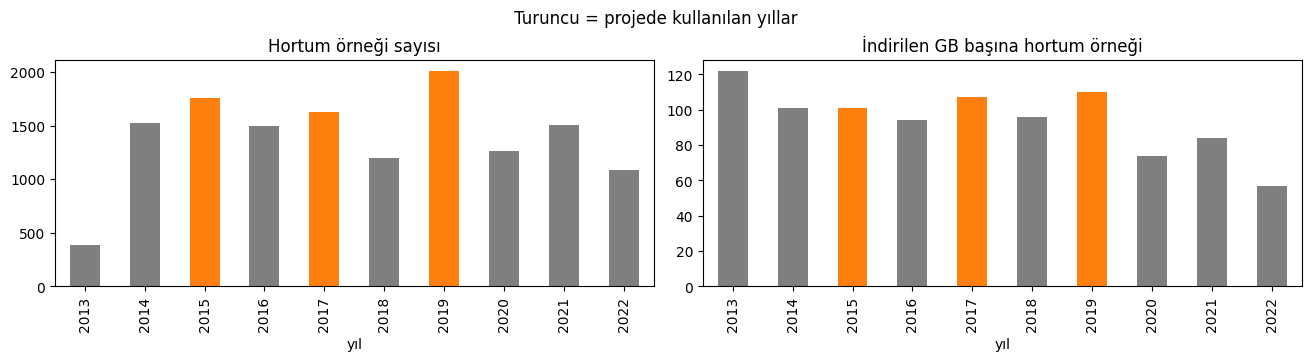

Yıllar: [2015, 2017, 2019] | 68,314 örnek | 5,388 hortum (%7.9)


category,NUL,TOR,WRN,All
type,,,,
test,5988,797,4293,11078
train,33030,4591,19615,57236
All,39018,5388,23908,68314


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5), layout="constrained")
colors = ["C1" if y in cfg["years"] else "C7" for y in per_year.index]
per_year["TOR"].plot.bar(ax=axes[0], color=colors)
axes[0].set_title("Hortum örneği sayısı")
per_year["TOR_per_GB"].plot.bar(ax=axes[1], color=colors)
axes[1].set_title("İndirilen GB başına hortum örneği")
for ax in axes:
    ax.set_xlabel("yıl")
fig.suptitle("Turuncu = projede kullanılan yıllar")
plt.show()

sel = cat[cat["year"].isin(cfg["years"])]
print("Yıllar:", cfg["years"], f"| {len(sel):,} örnek | {sel['label'].sum():,} hortum (%{100*sel['label'].mean():.1f})")
pd.crosstab(sel["type"], sel["category"], margins=True)

### B3. Hortum şiddeti (EF ölçeği)

EF (Geliştirilmiş Fujita) ölçeği hortumun şiddetini, bıraktığı hasara bakarak EF0 (en zayıf) ile EF5 (en güçlü) arasında derecelendirir; verimizde EF5 yok. Hortumların çoğu zayıf (EF0–EF1). Güçlü hortumlar (EF3–EF4) çok nadir; 2017'de hiç EF4 yok.

In [10]:
tor = cat[cat["category"] == "TOR"]
pd.crosstab(tor["year"], tor["ef_number"].astype(int), margins=True)

ef_number,0,1,2,3,4,All
year,,,,,,
2013,73,128,144,25,19,389
2014,611,559,206,114,39,1529
2015,752,712,199,69,22,1754
2016,603,575,214,92,17,1501
2017,602,747,236,38,0,1623
2018,538,473,145,39,0,1195
2019,745,818,299,138,11,2011
2020,505,526,164,43,25,1263
2021,572,640,216,59,21,1508


### B4. Eğitim/test ayrımı ve sızıntı kontrolü

`type` sütunundaki ayrımı veri setini hazırlayan MIT ekibi yapmış. Aynı fırtına olayı (`episode_id`) iki tarafta da varsa model sınavda daha önce gördüğü bir fırtınayla karşılaşır (**veri sızıntısı**). Ortak fırtınalar eğitimden çıkarılacak. Aşağıdaki sayılar 10 yılın tamamı için; bizim kullandığımız 3 yılda ortak fırtına sayısı 7, örnek sayısı 58. Bölme ve kontrolleri `02_preprocess.ipynb` defterinde.

In [11]:
train_eps = set(cat.loc[cat["type"] == "train", "episode_id"])
test_eps = set(cat.loc[cat["type"] == "test", "episode_id"])
overlap = train_eps & test_eps
print(f"test fırtınası: {len(test_eps):,} | eğitimde de olan: {len(overlap)}")
print(f"bu fırtınalara ait eğitim örneği: {cat[(cat['type']=='train') & cat['episode_id'].isin(overlap)].shape[0]}")

test fırtınası: 1,780 | eğitimde de olan: 25
bu fırtınalara ait eğitim örneği: 296


## C. Radar görüntülerini tanıma

### C0. Ham veriden örnek okuma

2017 arşivinin başından **1.500 örnek** okuyoruz (arşivin tamamı 15 GB; bu kısım ~1 GB). Bu örnekler C ve D bölümlerinde kullanılacak. Her örnek için D bölümündeki ölçüler de bu sırada hesaplanır.

Önce örneğin **temsil edici** olup olmadığına bakalım: TOR/WRN/NUL oranları 2017'nin tamamıyla benzer olmalı.

In [12]:
scan = eda.scan_archive(tornet.tar_url(2017), cat, n_files=1500)
feat = scan["features"]

rep = pd.DataFrame({
    "okunan 1.500 örnek (%)": (100 * feat["category"].value_counts(normalize=True)).round(1),
    "2017'nin tamamı (%)": (100 * cat[cat["year"] == 2017]["category"].value_counts(normalize=True)).round(1),
})
rep

örnek okunuyor:   0%|          | 0/1500 [00:00<?, ?dosya/s]

,okunan 1.500 örnek (%),2017'nin tamamı (%)
category,,
NUL,55.1,54.1
WRN,37.4,37.9
TOR,7.5,8.1


### C1. Grafik nasıl okunur?

**Eksenler:** Radar (0, 0) noktasında, çoğu zaman grafiğin dışında kalır. Yatay eksen radarın kaç km doğusunda, dikey eksen kaç km kuzeyinde olduğunu gösterir. Görüntü **yelpaze dilimi** şeklindedir, çünkü radar dönerek tarar ve bize fırtınanın çevresindeki 60° × 60 km'lik bir dilim verilmiştir.

**DBZ: yağış yoğunluğu**

| Renk | Değer | Anlamı |
|---|---|---|
| Mavi | 0–15 dBZ | Çok hafif yağış |
| Yeşil | 20–30 dBZ | Hafif-orta yağmur |
| Sarı-turuncu | 35–45 dBZ | Kuvvetli yağmur |
| Kırmızı | 50+ dBZ | Çok şiddetli yağmur, dolu |

**VEL: rüzgarın radara göre hızı**

| Renk | Anlamı |
|---|---|
| Kırmızı | Rüzgar radardan **uzaklaşıyor** |
| Mavi | Rüzgar radara **yaklaşıyor** |
| Beyaz | Hız sıfıra yakın |

**WIDTH: hız dağınıklığı**

| Renk | Anlamı |
|---|---|
| Koyu (siyah-mor) | Sakin, düzenli hava |
| Açık (turuncu-sarı) | Türbülans, hızlar çok dağınık |

**Hortumun imzası:** Hortum dönen bir hava sütunudur. Bir yanı radara yaklaşır, öbür yanı uzaklaşır. Bu yüzden VEL'de **güçlü mavi ile güçlü kırmızı yan yana** durur (**hız çifti**). Aynı yerde WIDTH de yükselir.

```
   🟦🟦🟥🟥   ← yan yana yaklaşan ve uzaklaşan rüzgar = dönme
   🟦🟦🟥🟥
```

**Siyah daire:** Kod, görüntünün merkezinde VEL'deki en güçlü hız çiftini bulup üç grafikte de aynı yeri daire içine alır.

Beyaz (boş) alanlar ölçüm olmayan yerlerdir: orada yağış ya da yansıma yoktur.

### C2. Güçlü bir hortum (EF2 ve üstü)

Okunan hortum örnekleri arasından EF2 ve üstü olan ve dönmesi en güçlü olanı seçiyoruz. Hız çifti bu örneklerde net görünür.

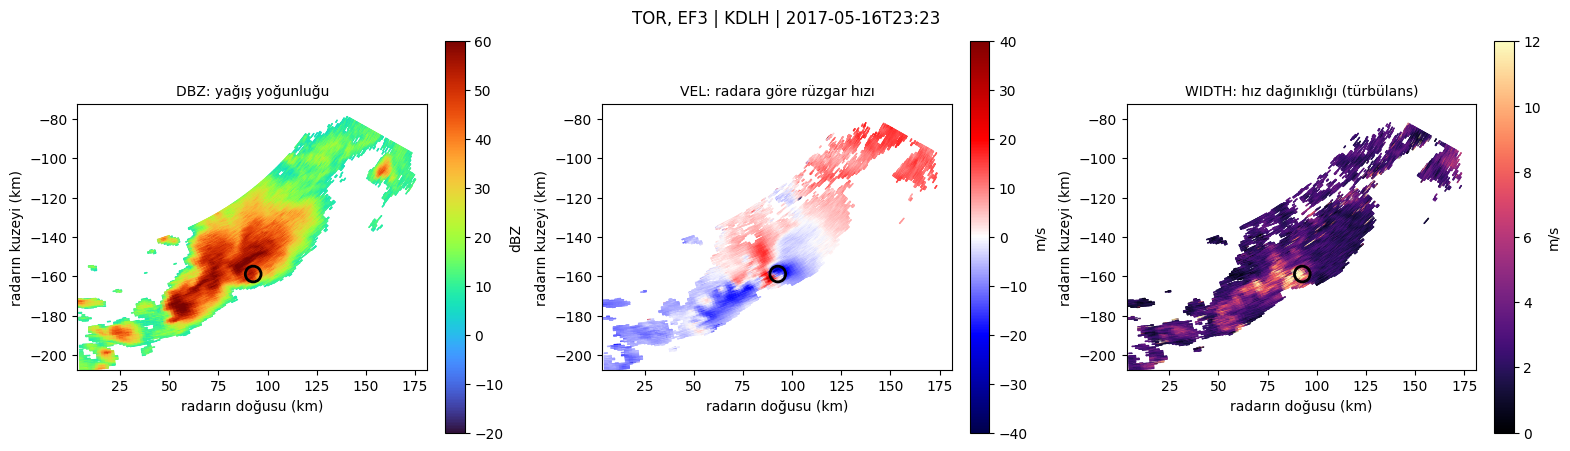

In [13]:
meta = cat.set_index("filename")
tor_raw = {n: b for n, b in scan["raw"].items() if "/TOR_" in n}
tor_info = pd.DataFrame({
    "ef": [meta.at[n, "ef_number"] for n in tor_raw],
    "dönme_gücü": [feat.set_index("filename").at[n, "VEL_s0"] for n in tor_raw],
}, index=list(tor_raw))

strong_name = tor_info[tor_info["ef"] >= 2].sort_values("dönme_gücü", ascending=False).index[0]
strong = tornet.open_sample(tor_raw[strong_name])
viz.plot_sample(strong)
plt.show()

### C3. Zayıf hortum, uyarı ve rastgele fırtına

Karşılaştırma için:

* **Zayıf hortum (EF0):** Dönme o kadar küçük ki çoğu zaman bu çözünürlükte görünmez. Model için en zor örnekler bunlar.
* **Uyarı (WRN):** Tehlikeli görünen ama hortum çıkmayan fırtına.
* **Rastgele fırtına (NUL):** Çoğunlukla sakin.

Dairenin bu örneklerde de çizildiğine dikkat: kod her zaman "en güçlü dönme"yi işaretler. Hortum olmayan örneklerde orada belirgin bir hız çifti yoktur.

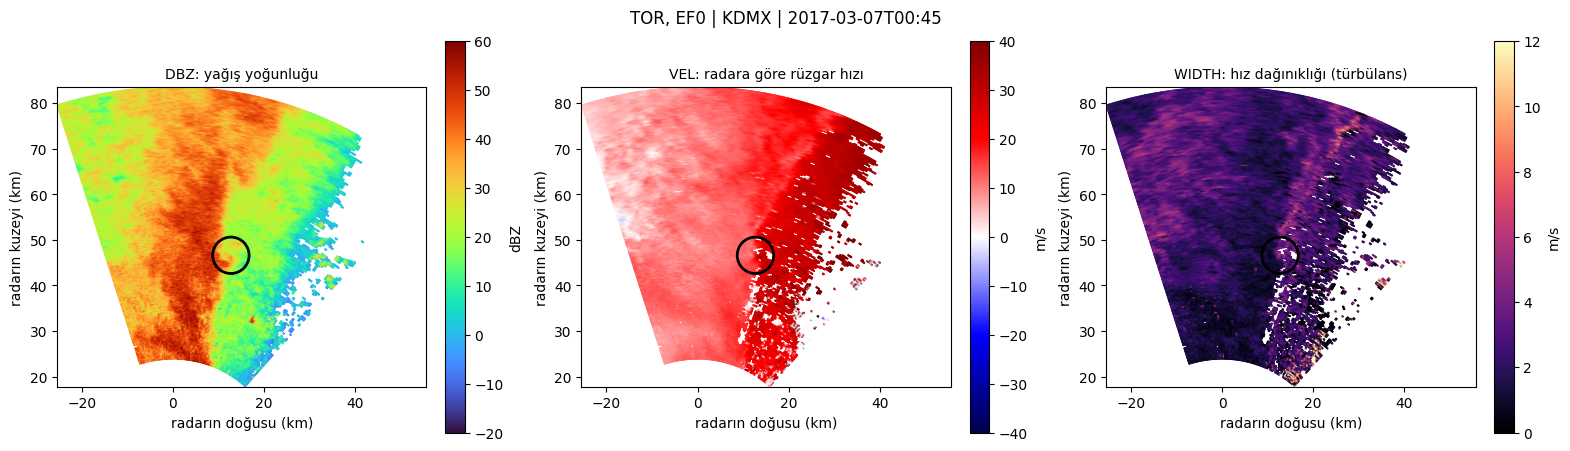

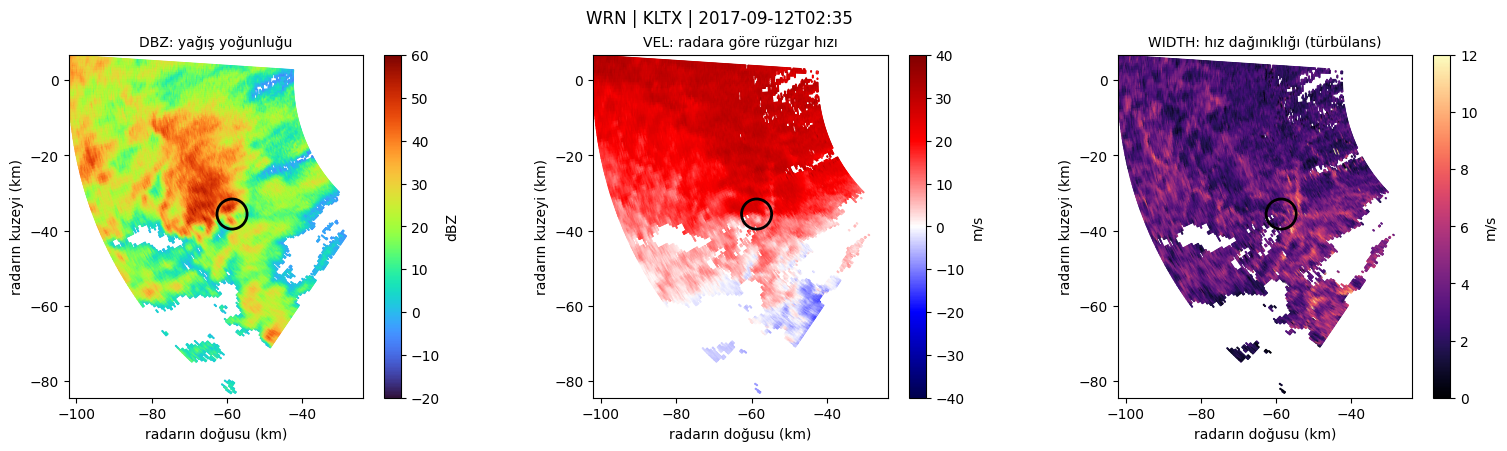

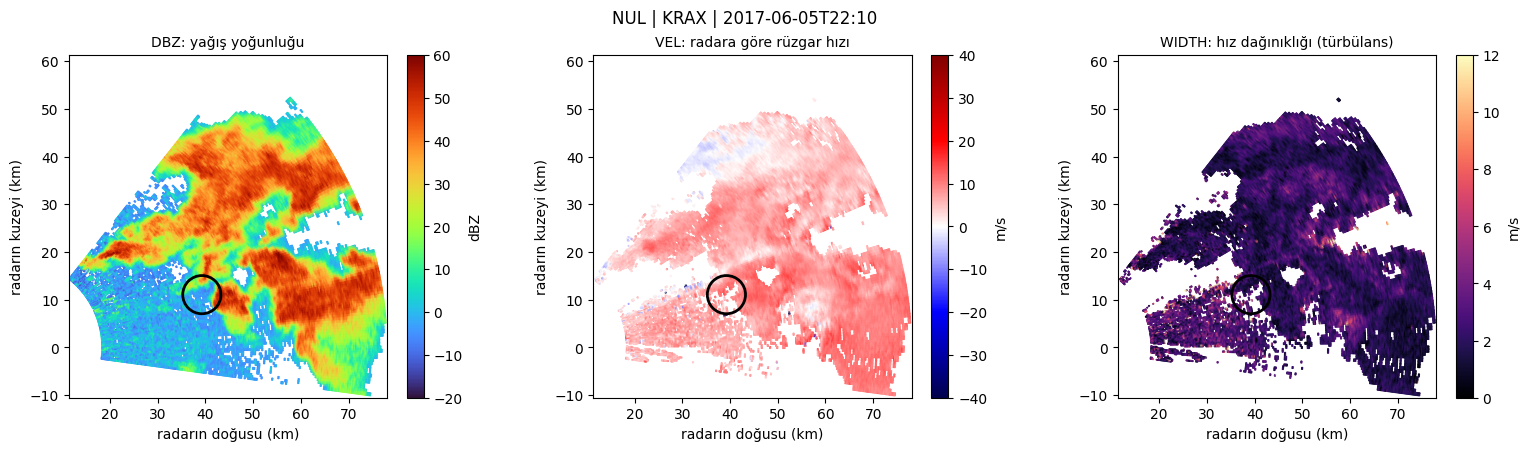

In [14]:
weak_name = tor_info[tor_info["ef"] == 0].sort_values("dönme_gücü").index[len(tor_info[tor_info["ef"] == 0]) // 2]
wrn_name = next(n for n in scan["raw"] if "/WRN_" in n)
nul_name = next(n for n in scan["raw"] if "/NUL_" in n)
for name in (weak_name, wrn_name):
    raw = scan["raw"][name]
    viz.plot_sample(tornet.open_sample(raw))
    plt.show()
viz.plot_sample(tornet.open_sample(scan["raw"][nul_name]))
plt.show()

### C4. Güçlü hortumun 4 zaman adımı

`frame_labels` hortumun yerde olduğu kareleri işaretler (başlıklardaki `etiket`). Örneğin etiketi **son** karenin etiketidir.

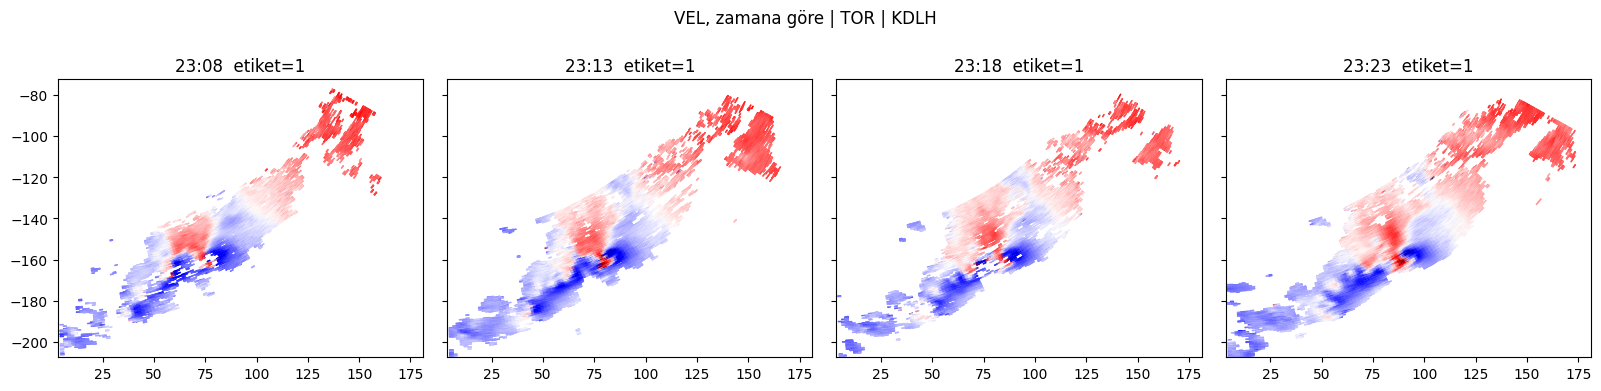

In [15]:
viz.plot_frames(strong, "VEL")
plt.show()

## D. Ham veri analizi: kararların kanıtı

Bu bölümde C0'da okunan 1.500 örneğin hepsi kullanılıyor. Her soru bir ön işleme kararına karşılık geliyor.

### D1. Boş piksel oranı

Radar her yeri ölçemez: yağış yoksa yansıma da yoktur. Tablo, her değişkende piksellerin yüzde kaçının boş (NaN) olduğunu gösteriyor (en alçak tarama, son kare).

In [16]:
nan_cols = [f"{v}_s0_nan" for v in eda.VARIABLES]
nan_table = (100 * feat.groupby("category")[nan_cols].mean()).round(1)
nan_table.columns = eda.VARIABLES
nan_table

,DBZ,VEL,KDP,RHOHV,ZDR,WIDTH
category,,,,,,
NUL,45.0,54.8,51.6,45.5,0.7,54.8
TOR,25.2,34.2,34.2,25.5,2.6,34.2
WRN,31.0,40.3,37.3,31.2,0.6,40.3


* Boşluklar her değişkende var, bu yüzden ön işlemede boş pikselleri **doldurmak zorundayız** (model "boş" değeri anlayamaz).
* VEL ve WIDTH'in boşlukları aynı, çünkü ikisi de aynı Doppler ölçümünden gelir.
* Hortum örneklerinde boşluk daha az: hortumlu fırtınalar daha geniş ve yoğun.

### D2. Değer dağılımları ve ölçekleme aralıkları

Modele vermeden önce her kanalı sabit bir aralıkla [-1, 1]'e ölçekleyeceğiz. Aralık verinin neredeyse tamamını kapsamalı; dışında kalan değerler aralığın sınırına kırpılır. Kesikli çizgiler seçtiğimiz aralığı gösteriyor.

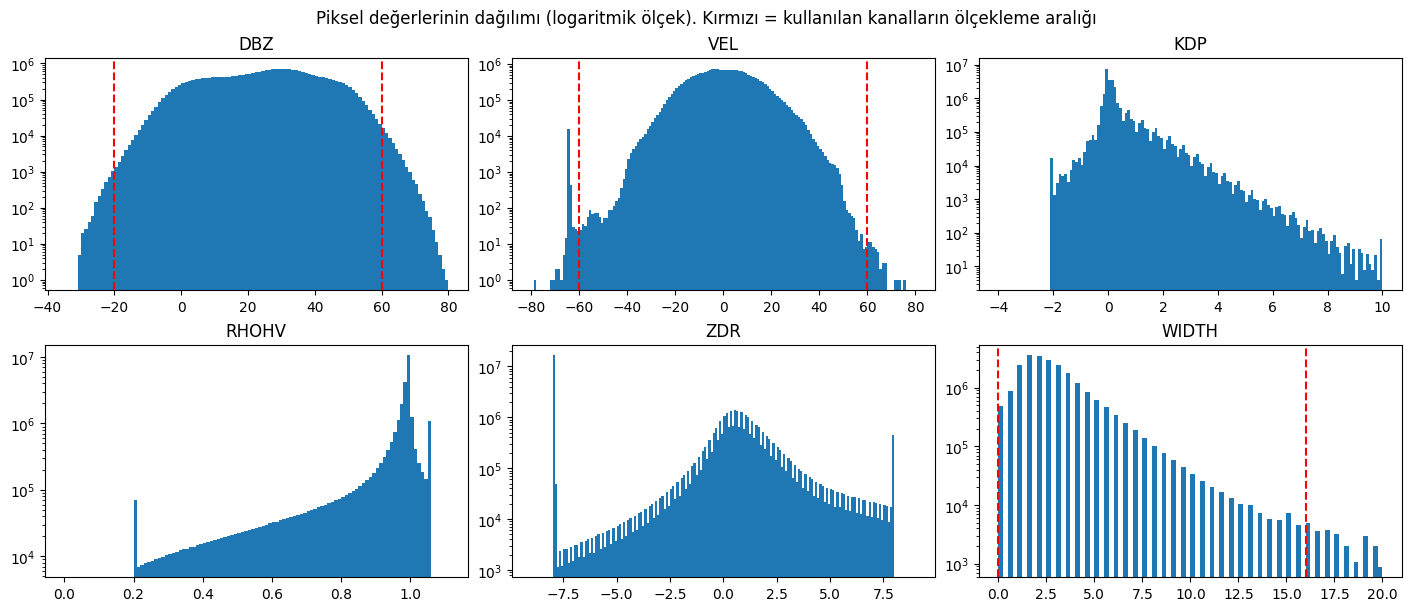

,aralık,aralık dışı piksel (%)
DBZ,"(-20.0, 60.0)",0.19
VEL,"(-60.0, 60.0)",0.07
WIDTH,"(0.0, 16.0)",0.09


In [17]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6), layout="constrained")
for ax, v in zip(axes.flat, eda.VARIABLES):
    bins = eda.HIST_BINS[v]
    ax.bar(bins[:-1], scan["hists"][v], width=np.diff(bins), align="edge", color="C0")
    ax.set_yscale("log")
    ax.set_title(v)
    if v in tornet.CHANNEL_RANGES and v in cfg["variables"]:
        for b in tornet.CHANNEL_RANGES[v]:
            ax.axvline(b, color="red", ls="--")
fig.suptitle("Piksel değerlerinin dağılımı (logaritmik ölçek). Kırmızı = kullanılan kanalların ölçekleme aralığı")
plt.show()

pd.DataFrame({
    v: {"aralık": str(tornet.CHANNEL_RANGES[v]),
        "aralık dışı piksel (%)": round(100 * scan["outside"][v][0] / scan["outside"][v][1], 2)}
    for v in scan["outside"]
}).T

**WIDTH aralığı neden 0–16?** Hortumda tam da yüksek WIDTH değerlerini (türbülans) bekliyoruz, bu yüzden üst sınır bu değerleri kırpmamalı. Aşağıdaki hücre farklı üst sınırlar için kırpılacak piksel oranını hesaplıyor. 16 ile piksellerin %99,9'u aralığın içinde kalıyor.

In [18]:
bins, counts = eda.HIST_BINS["WIDTH"], scan["hists"]["WIDTH"]
for hi in (9, 12, 16):
    print(f"WIDTH 0–{hi} aralığının dışında kalan piksel: %{100 * counts[bins[:-1] >= hi].sum() / counts.sum():.2f}")

WIDTH 0–9 aralığının dışında kalan piksel: %1.27
WIDTH 0–12 aralığının dışında kalan piksel: %0.39
WIDTH 0–16 aralığının dışında kalan piksel: %0.11


### D3. Hangi değişken hortumu ayırt ediyor?

Her örnek için her değişkenden **tek bir sayı** hesaplıyoruz. Görüntünün merkezinde (15° × 15 km), gürültü temizlendikten sonra (ayrıntılar `src/helper/eda.py`'de):

| Değişken | Ölçü | Neden bu ölçü? |
|---|---|---|
| DBZ | en yüksek değerler (99. yüzdelik) | Güçlü fırtına = yüksek yansıtıcılık |
| VEL | **dönme gücü**: küçük bir pencerede en büyük hız farkı | Hortum = hız çifti |
| WIDTH, KDP | en yüksek değerler (99. yüzdelik) | Türbülans / yoğun yağış |
| RHOHV, ZDR | en düşük değerler (1. yüzdelik) | Enkaz bu değerleri düşürür |

Sonra her ölçünün hortumu ne kadar ayırt ettiğini **AUC** ile puanlıyoruz:

* **0,5:** Ölçü hortumu hiç ayırt etmiyor (yazı tura).
* **1,0:** Mükemmel ayırt ediyor.
* **0,5'in altı:** Ters yönde ayırt ediyor (hortumda daha düşük). Bu yüzden "ayırt etme gücü" = max(AUC, 1 − AUC) da veriliyor.

İki karşılaştırma yapıyoruz:

* **Hortumu ayırt etme:** TOR örnekleri, hortumsuz örneklerin hepsiyle (WRN + NUL) karşılaştırılır.
* **Yanlış alarmlardan ayırt etme:** TOR örnekleri sadece WRN örnekleriyle (uyarı verilmiş ama hortum çıkmamış fırtınalar) karşılaştırılır. Bu en zor durum, çünkü bu fırtınalar hortumlu olanlara çok benziyor.

**Not:** Model yine iki sınıflıdır: hortum = 1, diğer her şey (yanlış alarmlar dahil) = 0. İkinci karşılaştırma ayrı bir sınıf değil, sadece bir analizdir: değişkenin hortuma özgü bir şey ölçüp ölçmediğini gösterir.

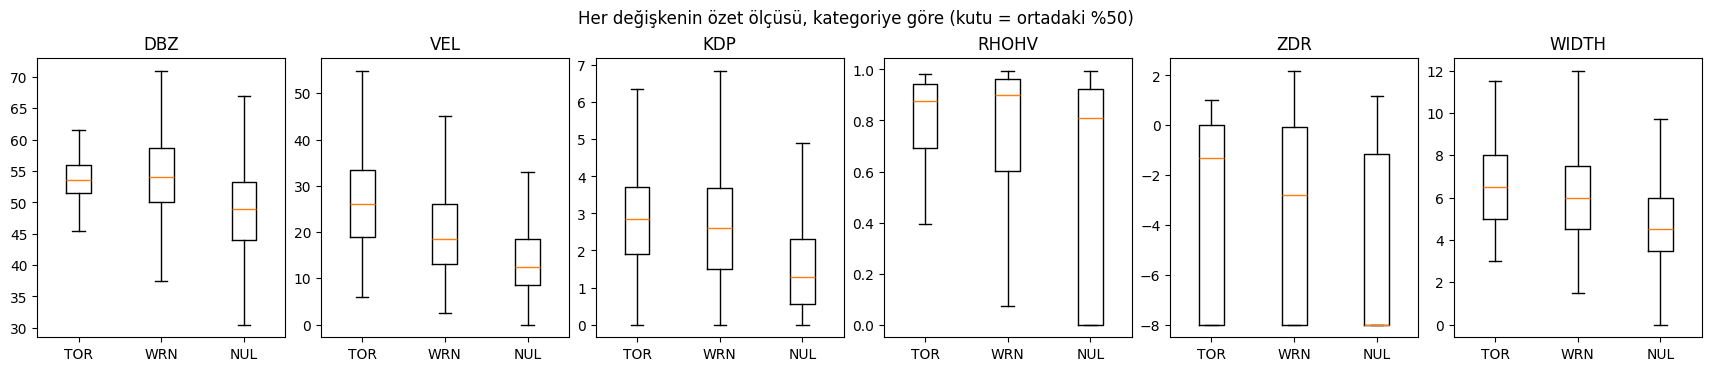

,Hortumu ayırt etme (AUC),ayırt etme gücü,Yanlış alarmlardan ayırt etme (AUC),ayırt etme gücü
VEL,0.764,0.764,0.685,0.685
WIDTH,0.685,0.685,0.582,0.582
KDP,0.677,0.677,0.540,0.540
DBZ,0.624,0.624,0.480,0.520
ZDR,0.611,0.611,0.533,0.533
RHOHV,0.541,0.541,0.462,0.538


In [19]:
cols0 = [f"{v}_s0" for v in eda.VARIABLES]
fig, axes = plt.subplots(1, 6, figsize=(17, 3.6), layout="constrained")
order = ["TOR", "WRN", "NUL"]
for ax, c, v in zip(axes, cols0, eda.VARIABLES):
    data = [feat.loc[feat["category"] == k, c].dropna() for k in order]
    ax.boxplot(data, showfliers=False)
    ax.set_xticks([1, 2, 3], order)
    ax.set_title(v)
fig.suptitle("Her değişkenin özet ölçüsü, kategoriye göre (kutu = ortadaki %50)")
plt.show()

auc_all = eda.separability(feat, cols0)
auc_wrn = eda.separability(feat, cols0, negative=("WRN",))
auc_table = pd.DataFrame({
    "Hortumu ayırt etme (AUC)": auc_all["AUC"],
    "ayırt etme gücü": auc_all["ayırt etme gücü"],
    "Yanlış alarmlardan ayırt etme (AUC)": auc_wrn["AUC"],
    "ayırt etme gücü ": auc_wrn["ayırt etme gücü"],
})
auc_table.index = eda.VARIABLES
auc_table.sort_values("ayırt etme gücü", ascending=False)

### D3b. Ölçümler birlikte ne kadar işe yarıyor?

Yukarıdaki AUC **tek değişkenli**: her ölçüme ayrı ayrı bakıyor. Tek başına zayıf görünen bir ölçüm, başka ölçümlerle birlikte işe yarayabilir. Bunu görmek için ölçümlerin özet sayılarını **birlikte** iki basit modele veriyoruz:

* **Lojistik regresyon:** Ölçümleri doğrusal olarak birleştirir.
* **Random forest:** Ölçümler arasındaki etkileşimleri de yakalayabilir (ör. "dönme güçlü VE türbülans yüksek").

Farklı ölçüm gruplarını karşılaştırıyoruz. Seçtiğimiz 3 ölçüm, 6 ölçümün hepsine yakın sonuç veriyorsa bilginin çoğu seçtiklerimizde demektir.

Sonuçlar **çapraz doğrulamayla** hesaplanıyor: örnekler 5 parçaya bölünüyor, model 4 parçayla eğitilip 5.'de ölçülüyor, bu her parça için tekrarlanıyor. Bölme **fırtınaya göre** yapılıyor (aynı fırtına hem eğitim hem ölçüm tarafında olmasın) ve 5 farklı karıştırmayla tekrarlanıyor. Tabloda ortalama ve sapma (±) var.

In [20]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

feat["episode_id"] = cat.set_index("filename").loc[feat["filename"], "episode_id"].to_numpy()

groups = {
    "VEL": ["VEL_s0"],
    "VEL + WIDTH": ["VEL_s0", "WIDTH_s0"],
    "DBZ + VEL + WIDTH (seçilen)": ["DBZ_s0", "VEL_s0", "WIDTH_s0"],
    "6 ölçüm (0,5°)": [f"{v}_s0" for v in eda.VARIABLES],
    "6 ölçüm × 2 açı": [f"{v}_s{s}" for v in eda.VARIABLES for s in (0, 1)],
}
models = {
    "Lojistik regresyon": lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                                LogisticRegression(class_weight="balanced", max_iter=1000)),
    "Random forest": lambda: make_pipeline(SimpleImputer(strategy="median"),
                                           RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                                  class_weight="balanced", random_state=0, n_jobs=-1)),
}

rows = []
for gname, cols in groups.items():
    row = {"ölçüm grubu": gname, "özellik sayısı": len(cols)}
    for mname, make in models.items():
        scores = []
        for seed in range(5):
            cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
            scores += list(cross_val_score(make(), feat[cols], feat["label"], groups=feat["episode_id"],
                                           cv=cv, scoring="roc_auc"))
        row[mname] = f"{np.mean(scores):.3f} ± {np.std(scores):.3f}"
    rows.append(row)
pd.DataFrame(rows).set_index("ölçüm grubu")

,özellik sayısı,Lojistik regresyon,Random forest
ölçüm grubu,,,
VEL,1,0.765 ± 0.044,0.693 ± 0.055
VEL + WIDTH,2,0.762 ± 0.044,0.732 ± 0.044
DBZ + VEL + WIDTH (seçilen),3,0.760 ± 0.044,0.745 ± 0.043
"6 ölçüm (0,5°)",6,0.785 ± 0.050,0.777 ± 0.046
6 ölçüm × 2 açı,12,0.784 ± 0.048,0.773 ± 0.048


### Kanal seçimi

D3'teki tek değişkenli tablo ve kutu grafikleri şunu gösteriyor (bizim çalıştırmamızdaki değerlerle):

* **VEL açık ara en iyi** (≈0,76). En zor durumda, hortumu yanlış alarmlardan ayırmada da en iyisi (≈0,69). Hortumun ana imzası olan hız çifti bu kanalda. → **Seçildi.**
* **WIDTH ikinci** (≈0,69). Dönme ve türbülans hızların dağınıklığını artırıyor. → **Seçildi.**
* **DBZ** "fırtına var mı?" sorusunda bir miktar işe yarıyor (≈0,62) ama **hortumu yanlış alarmlardan ayıramıyor** (≈0,48). Ancak bu ölçü görüntüyü tek bir sayıya indiriyor; DBZ'nin asıl bilgisi **şekilde** (kanca), ve onu tek sayı ölçemez, CNN görebilir. Meteorolojide de hortum tespitinin standart kanalı. → **Seçildi.**
* **KDP** DBZ ile aynı türden bilgi taşıyor (yağış yoğunluğu). **RHOHV** ve **ZDR**'nin ayırt ediciliği düşük; bunların asıl sinyali güçlü hortumların kaldırdığı enkaz, ve verimizin çoğu zayıf hortum. → **Alınmadı.**

D3b'deki çok değişkenli tablo da şunu gösteriyor (bizim çalıştırmamızdaki değerlerle):

* **Seçilen 3 ölçüm birlikte ≈0,75–0,76**, **6 ölçümün hepsi ≈0,78** AUC veriyor. Dışarıda bırakılan 3 ölçüm birlikteyken **küçük bir katkı** (≈0,02–0,03) sağlıyor; bu fark, çapraz doğrulama katları arasındaki dalgalanmadan (±0,05) küçük.
* **İkinci tarama açısını eklemek** (12 özellik) sonucu iyileştirmiyor → en alçak açı seçimini destekliyor (D4).
* Bu özet sayılarla **VEL tek başına bile** seçilen üçlüye yakın: tek sayıya indirilmiş bilginin çoğu VEL'de.

**Sonuç:** Model **DBZ + VEL + WIDTH** (3 kanal) ile eğitilecek.

**Bu analizin sınırı:** D3 ve D3b her görüntüyü birkaç özet sayıya indiriyor. Kanca şekli gibi **uzamsal desenleri** göremez; onları ancak görüntünün tamamına bakan bir model, yani CNN görebilir. Bu yüzden kanalların gerçek katkısı ayrıca CNN ile bir eğitim deneyinde sınanabilir; D3b'deki küçük fark, 6 kanallı bir CNN denemesinin de değerlendirilebileceğini gösteriyor.

**Ölçüleri neden merkezde hesapladık?** Aşağıdaki hücre, görüntünün tamamında en güçlü dönmenin nerede olduğuna bakıyor. Hortum örneklerinde en güçlü dönme çok daha sık merkezde: veri seti, olayın konumu görüntünün ortasında olacak şekilde kesilmiş.

In [21]:
center = (feat["rot_az"].between(45, 74)) & (feat["rot_rng"].between(90, 149))
(100 * center.groupby(feat["category"]).mean()).round(1).rename("en güçlü dönme merkezde (%)").to_frame()

,en güçlü dönme merkezde (%)
category,
NUL,10.8
TOR,41.6
WRN,26.7


### D4. Hangi tarama açısı?

Aynı ölçüler iki tarama açısında: 0,5° (yere en yakın) ve 0,9°. Radar ışını uzaklaştıkça yükseldiği için alçak tarama yere, yani hortuma daha yakın bakar.

In [22]:
cols1 = [f"{v}_s1" for v in eda.VARIABLES]
sweeps = pd.DataFrame({
    "0,5° (AUC)": eda.separability(feat, cols0)["ayırt etme gücü"].values,
    "0,9° (AUC)": eda.separability(feat, cols1)["ayırt etme gücü"].values,
}, index=eda.VARIABLES)
sweeps["fark"] = (sweeps["0,5° (AUC)"] - sweeps["0,9° (AUC)"]).round(3)
sweeps

,"0,5° (AUC)","0,9° (AUC)",fark
DBZ,0.624,0.624,0.000
VEL,0.764,0.746,0.018
KDP,0.677,0.703,-0.026
RHOHV,0.541,0.528,0.013
ZDR,0.611,0.606,0.005
WIDTH,0.685,0.662,0.023


İki tarama arasındaki farklar küçük. En önemli kanal olan VEL'de alçak tarama biraz daha iyi. Fiziksel gerekçe de alçak taramadan yana. İkisini birden almak veriyi iki katına çıkarırdı; bu yüzden **en alçak tarama (0,5°)** seçildi.

### D5. Hangi zaman adımı?

Her örnekte 4 kare var. Etiketin hangi kareden geldiğini ve hortumun hangi karede başladığını kontrol edelim.

In [23]:
t = feat[feat["category"] == "TOR"]
print("TOR örneklerinde son karenin etiketi 1 mi?        ", (t["last_label"] == 1).all())
print("TOR olmayan örneklerde bütün kareler 0 mı?        ", (feat.loc[feat["category"] != "TOR", "n_tor_frames"] == 0).all())
frames = t["first_tor_frame"].value_counts().sort_index()
frames.index = [f"{i + 1}. kare" for i in frames.index]
frames.rename("hortumun başladığı kare (örnek sayısı)").to_frame()

TOR örneklerinde son karenin etiketi 1 mi?         True
TOR olmayan örneklerde bütün kareler 0 mı?         True


,hortumun başladığı kare (örnek sayısı)
1. kare,10
2. kare,15
3. kare,41
4. kare,47


* Etiket **son karenin** etiketi: bütün TOR örneklerinde son kare 1, diğer örneklerde bütün kareler 0.
* Hortumların çoğu ancak son karelerde başlıyor; önceki karelerde henüz hortum yok.

"Şu an hortum var mı?" sorusuna cevap aradığımız için **son kare** seçildi. Önceki kareler ileride (RNN/LSTM haftaları) hortumun oluşumunu modellemek için kullanılabilir.

### D6. Ölçüm hassasiyeti

Ön işlemede veriyi küçültmek için her pikseli 0–255 arası tam sayıya (`uint8`) çevireceğiz. Bu, değerleri 254 adıma yuvarlamak demek. Bilgi kaybedip kaybetmediğimizi anlamak için radarın veriyi hangi hassasiyetle kaydettiğine bakalım.

In [24]:
rows = []
for v in cfg["variables"]:
    lo, hi = tornet.CHANNEL_RANGES[v]
    rows.append({
        "kanal": v,
        "radarın kaydettiği en sık adım": scan["steps"][v].index[0],
        "uint8 adımı": round((hi - lo) / 254, 3),
        "en büyük yuvarlama hatası": round((hi - lo) / 254 / 2, 3),
    })
pd.DataFrame(rows).set_index("kanal")

,radarın kaydettiği en sık adım,uint8 adımı,en büyük yuvarlama hatası
kanal,,,
DBZ,0.5000,0.315,0.157
VEL,0.0625,0.472,0.236
WIDTH,0.5000,0.063,0.031


* **DBZ** ve **WIDTH** radarda 0,5'lik adımlarla kayıtlı; `uint8` adımımız daha ince, yani **bilgi kaybı yok.**
* **VEL**'de bazı değerler daha ince adımlarla kayıtlı. En büyük yuvarlama hatası ≈0,24 m/s; hortumdaki 20–60 m/s'lik hız farkları yanında önemsiz.

Bu kararlar `02_preprocess.ipynb` defterinde uygulanıyor.